# Exercise 3 — Bayes' & k-NN classifiers from scratch

Forest vs urban pixel classification using Sentinel-2 true-color crops from **ex1**
(Białowieża forest / Warsaw urban).

**Feature:** intensity $I = 0.299R + 0.587G + 0.114B$ (grayscale), so histograms and PDFs are 1-D and easy to interpret.

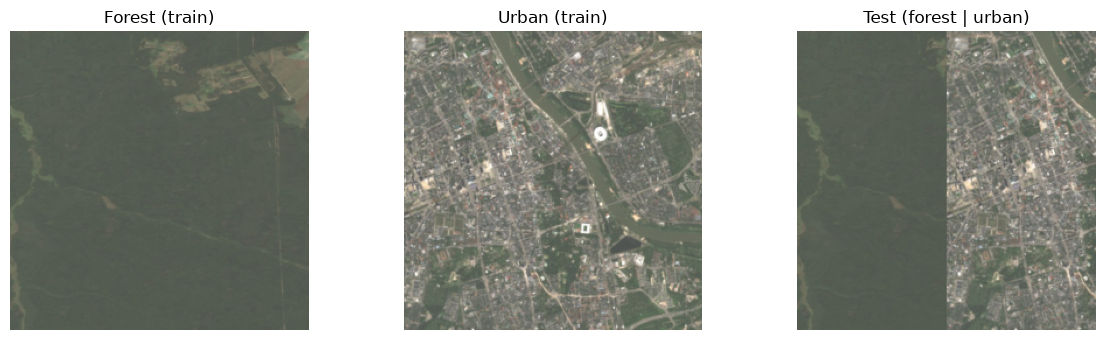

train forest pixels: 65536, urban: 65536, test: 65536


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = Path("../ex1/satellite_images")

def load_rgb(path, max_side=256):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = max_side / max(w, h)
    if scale < 1:
        img = img.resize((int(w * scale), int(h * scale)), Image.BILINEAR)
    return np.asarray(img, dtype=np.float64)

def to_intensity(rgb):
    return 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]

forest_rgb = load_rgb(IMG_DIR / "forest_poland.jpg")
urban_rgb  = load_rgb(IMG_DIR / "urban_poland.jpg")
forest_I = to_intensity(forest_rgb)
urban_I  = to_intensity(urban_rgb)

# Mixed test image: left = forest, right = urban
h = min(forest_rgb.shape[0], urban_rgb.shape[0])
w = min(forest_rgb.shape[1], urban_rgb.shape[1]) // 2
test_rgb = np.concatenate([forest_rgb[:h, :w], urban_rgb[:h, :w]], axis=1)
test_I = to_intensity(test_rgb)
true_mask = np.concatenate([
    np.zeros((h, w), dtype=bool),   # False = forest
    np.ones((h, w), dtype=bool),    # True  = urban
], axis=1)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].imshow(forest_rgb.astype(np.uint8)); ax[0].set_title("Forest (train)"); ax[0].axis("off")
ax[1].imshow(urban_rgb.astype(np.uint8));  ax[1].set_title("Urban (train)");  ax[1].axis("off")
ax[2].imshow(test_rgb.astype(np.uint8));   ax[2].set_title("Test (forest | urban)"); ax[2].axis("off")
plt.tight_layout(); plt.show()
print(f"train forest pixels: {forest_I.size}, urban: {urban_I.size}, test: {test_I.size}")

## Part 1 — Bayes classifier

### Steps
1. Build histograms of intensity for forest and urban training pixels.
2. Fit a **Gaussian** parametric PDF for each class:
   $$p(x\mid\omega_i)=\frac{1}{\sqrt{2\pi}\,\sigma_i}\exp\!\left(-\frac{(x-\mu_i)^2}{2\sigma_i^2}\right)$$
3. Assume equal priors $P(\omega_F)=P(\omega_U)=1/2$.
4. **Bayes test** for each pixel $x$: assign forest if $p(x\mid\omega_F) > p(x\mid\omega_U)$, else urban.
5. Color the decision map: **blue = forest**, **red = urban**.

Parametric PDF parameters (Gaussian):
  Forest:  μ = 91.51,  σ = 6.50
  Urban:   μ = 123.09,  σ = 22.99


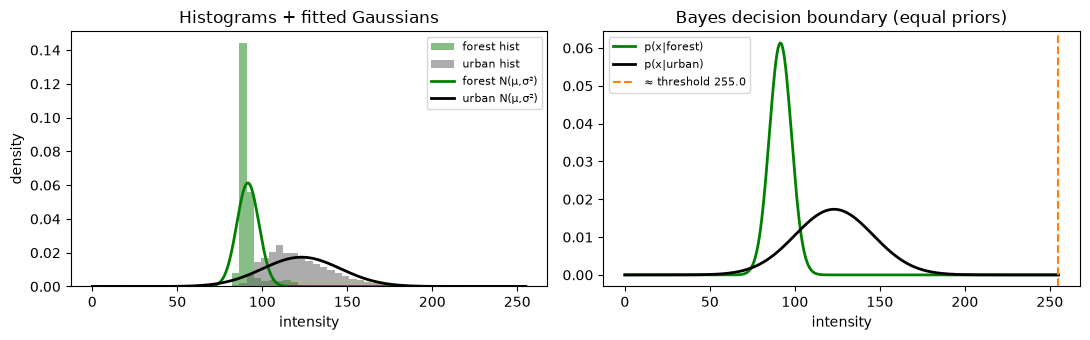

In [2]:
# --- histograms + Gaussian parameter estimation ---
mu_f, sig_f = forest_I.mean(), forest_I.std(ddof=1)
mu_u, sig_u = urban_I.mean(),  urban_I.std(ddof=1)

print("Parametric PDF parameters (Gaussian):")
print(f"  Forest:  μ = {mu_f:.2f},  σ = {sig_f:.2f}")
print(f"  Urban:   μ = {mu_u:.2f},  σ = {sig_u:.2f}")

def gauss_pdf(x, mu, sig):
    return (1.0 / (np.sqrt(2 * np.pi) * sig)) * np.exp(-0.5 * ((x - mu) / sig) ** 2)

bins = np.linspace(0, 255, 60)
xs = np.linspace(0, 255, 400)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(forest_I.ravel(), bins=bins, density=True, alpha=0.55, color="forestgreen", label="forest hist")
ax[0].hist(urban_I.ravel(),  bins=bins, density=True, alpha=0.55, color="dimgray",     label="urban hist")
ax[0].plot(xs, gauss_pdf(xs, mu_f, sig_f), "g-", lw=2, label="forest N(μ,σ²)")
ax[0].plot(xs, gauss_pdf(xs, mu_u, sig_u), "k-", lw=2, label="urban N(μ,σ²)")
ax[0].set_xlabel("intensity"); ax[0].set_ylabel("density")
ax[0].set_title("Histograms + fitted Gaussians"); ax[0].legend(fontsize=8)

# decision threshold (equal priors): where likelihoods cross
overlap = xs[np.argmin(np.abs(gauss_pdf(xs, mu_f, sig_f) - gauss_pdf(xs, mu_u, sig_u)))]
ax[1].plot(xs, gauss_pdf(xs, mu_f, sig_f), "g-", lw=2, label="p(x|forest)")
ax[1].plot(xs, gauss_pdf(xs, mu_u, sig_u), "k-", lw=2, label="p(x|urban)")
ax[1].axvline(overlap, color="C1", ls="--", label=f"≈ threshold {overlap:.1f}")
ax[1].set_xlabel("intensity"); ax[1].set_title("Bayes decision boundary (equal priors)")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

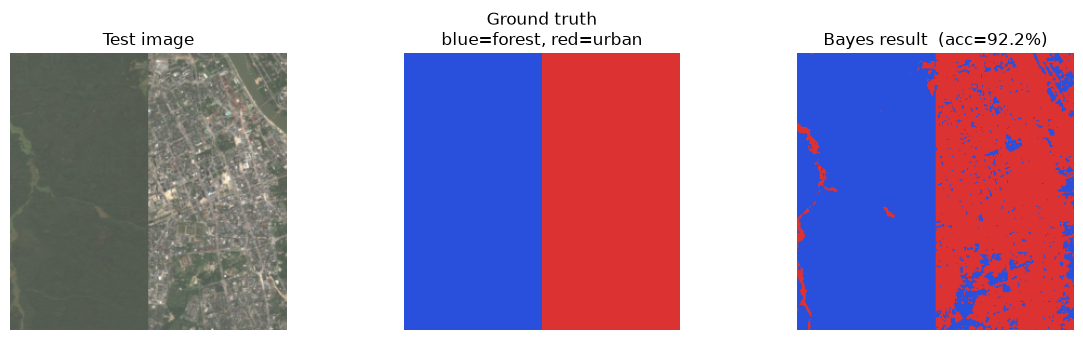

In [3]:
# --- Bayes pixel classification ---
def bayes_classify(I, mu_f, sig_f, mu_u, sig_u):
    """Return boolean mask: True = urban, False = forest."""
    lf = gauss_pdf(I, mu_f, sig_f)
    lu = gauss_pdf(I, mu_u, sig_u)
    return lu > lf  # equal priors → compare likelihoods

def colorize(mask_urban):
    """Blue = forest, red = urban."""
    out = np.zeros((*mask_urban.shape, 3), dtype=np.uint8)
    out[~mask_urban] = (40, 80, 220)   # forest → blue
    out[mask_urban]  = (220, 50, 50)   # urban  → red
    return out

bayes_mask = bayes_classify(test_I, mu_f, sig_f, mu_u, sig_u)
bayes_acc = (bayes_mask == true_mask).mean()

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].imshow(test_rgb.astype(np.uint8)); ax[0].set_title("Test image"); ax[0].axis("off")
ax[1].imshow(colorize(true_mask)); ax[1].set_title("Ground truth\nblue=forest, red=urban"); ax[1].axis("off")
ax[2].imshow(colorize(bayes_mask)); ax[2].set_title(f"Bayes result  (acc={bayes_acc:.1%})"); ax[2].axis("off")
plt.tight_layout(); plt.show()

**Bayes — what happened**

- Forest pixels are typically darker/greener → lower mean intensity than bright urban roofs/roads.
- The fitted Gaussians capture that shift; the Bayes test is a soft threshold on intensity (equal priors).
- Misclassifications appear where forest has bright gaps or urban has dark shadows — intensity alone is a limited feature.

## Part 2 — k-NN classifier (from scratch)

Same forest / urban problem. Feature = intensity (1-D), so distance is $|x - x'|$.

### Steps
1. Build a **training set**: subsample pixels from forest (label 0) and urban (label 1).
2. For each test pixel $x$, find the $k$ nearest training samples (Euclidean / absolute distance).
3. Majority vote among those $k$ labels → class of $x$.
4. Repeat for $k \in \{1, 3, 5\}$ and compare.

k=1: accuracy = 91.6%
k=3: accuracy = 93.9%
k=5: accuracy = 94.7%


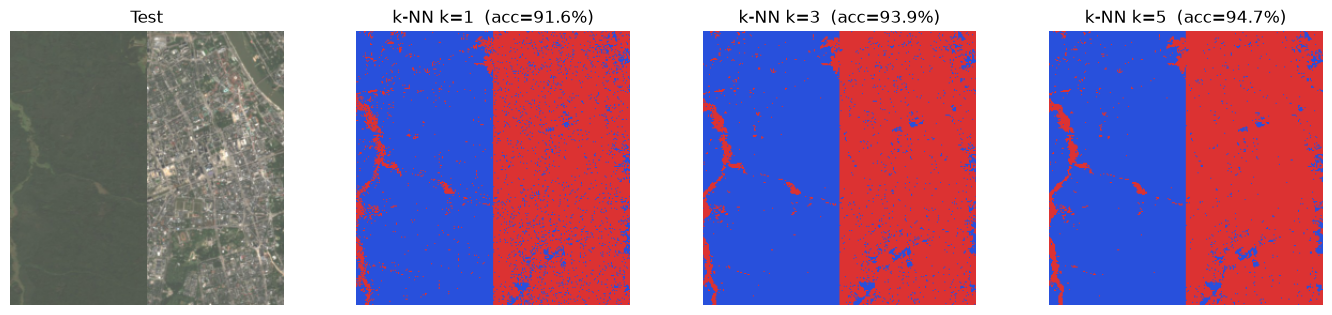

In [4]:
rng = np.random.default_rng(0)
N_PER_CLASS = 800  # keep k-NN tractable

def sample_pixels(I, n, rng):
    flat = I.ravel()
    idx = rng.choice(flat.size, size=n, replace=False)
    return flat[idx]

X_train = np.concatenate([
    sample_pixels(forest_I, N_PER_CLASS, rng),
    sample_pixels(urban_I,  N_PER_CLASS, rng),
])
y_train = np.concatenate([
    np.zeros(N_PER_CLASS, dtype=int),  # forest
    np.ones(N_PER_CLASS, dtype=int),   # urban
])

def knn_predict(X_test, X_train, y_train, k):
    """Brute-force k-NN. X_test, X_train are 1-D intensity arrays."""
    # distances: (n_test, n_train)
    d = np.abs(X_test[:, None] - X_train[None, :])
    nn = np.argpartition(d, kth=k - 1, axis=1)[:, :k]  # k nearest indices
    votes = y_train[nn]
    # majority: mean > 0.5 → urban
    return (votes.mean(axis=1) > 0.5).astype(int)

test_flat = test_I.ravel()
ks = [1, 3, 5]
knn_masks = {}
knn_accs = {}

for k in ks:
    pred = knn_predict(test_flat, X_train, y_train, k)
    mask = pred.reshape(test_I.shape).astype(bool)
    knn_masks[k] = mask
    knn_accs[k] = (mask == true_mask).mean()
    print(f"k={k}: accuracy = {knn_accs[k]:.1%}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
ax[0].imshow(test_rgb.astype(np.uint8)); ax[0].set_title("Test"); ax[0].axis("off")
for i, k in enumerate(ks):
    ax[i + 1].imshow(colorize(knn_masks[k]))
    ax[i + 1].set_title(f"k-NN k={k}  (acc={knn_accs[k]:.1%})")
    ax[i + 1].axis("off")
plt.tight_layout(); plt.show()

### Effect of $k$

| $k$ | Behaviour |
|-----|-----------|
| **1** | Very local: each pixel copies its single nearest neighbour → noisy, speckled map (overfits training sample). |
| **3** | Small majority vote smooths isolated errors; boundary stays fairly sharp. |
| **5** | Stronger smoothing: fewer speckles, slightly more bias near the decision edge / ambiguous intensities. |

In short: raising $k$ reduces variance (noise) and increases bias (smoothing). With 1-D intensity, Bayes (parametric) and mid-$k$ k-NN often look similar; k-NN does not assume a Gaussian shape, so it can follow multimodal histograms better if the feature were richer (e.g. full RGB).

## Summary

1. **Bayes:** estimate $\mu,\sigma$ per class from training histograms → Gaussian PDFs → per-pixel likelihood comparison → blue/red map.
2. **k-NN:** store labelled training intensities → for each test pixel, vote among $k$ nearest → maps for $k=1,3,5$.
3. Both reuse the same forest/urban Sentinel-2 crops; the test mosaic makes the left/right split easy to judge visually.